# BIM Uniform-Error Multi-Bid vs Single-Bid Terminal Bids

Select `scenario`, sample count, error range, bids, and `battery_view` in the configuration cell below. Use `nothing` for fleet totals or `"battery1"` / `"battery2"` for battery dispatch and surplus. System prices and costs always describe the whole market.

Generate matching results from the `code` directory:
```sh
julia --project=. --threads=1 -p 6 run_experiments.jl
```
Edit the function calls at the bottom of `run_experiments.jl` to set inputs, network, sample count, error range, seed, and terminal bids. The foresight loop selects standard bids, buy foresight, or both. Match this notebook's configuration to those settings (`scenario = "multiple_ess"` for `inputs_multiple_ess`). All available single-bid CSVs from the selected scenario are discovered automatically, sorted numerically by terminal bid, and plotted separately with labeled colors. Restart the kernel and run this notebook after generating results. Figures are saved in a directory specific to this configuration.

Each battery receives independent uniform errors for every sample and time interval. Buy foresight uses each battery's own reference charging schedule. Monetary system metrics repeat across battery rows in the CSV; the notebook counts each sample once and sums battery dispatch for fleet plots. Multibid prices come from an LP solve with optimal binary modes fixed. Surplus subtracts degradation costs.


In [23]:
import Pkg
Pkg.activate(joinpath(@__DIR__, ".."))
using Random
include(joinpath(@__DIR__, "plotting.jl"))


  Activating project at `~/projects/ferc_841_storage_models/code`


plot_charge_by_time

In [24]:
using CSV
using DataFrames
using Statistics
using StatsPlots


FIGURE_DIR = joinpath(@__DIR__, "..", "figures", "bim")
mkpath(FIGURE_DIR)

function dollar_formatter(x)
    n = Int(round(x))
    s = string(abs(n))
    parts = []
    while length(s) > 3
        pushfirst!(parts, s[end-2:end])
        s = s[1:end-3]
    end
    pushfirst!(parts, s)
    body = join(parts, ",")
    return n < 0 ? "-\$" * body : "\$" * body
end


dollar_formatter (generic function with 1 method)

In [25]:
# --- Scenario and plot selection: match the runner settings ---
scenario = "base"      # "base" or "multiple_ess"
n_samples = 10_000
error_range = 20.0
b = 0.0
battery_view = nothing         # nothing (fleet), "battery1", "battery2", or "battery" for base

# :each_battery allows different intervals; :same_interval requires a shared interval.
price_setting_mode = :each_battery

OUTPUT_DIR = joinpath(@__DIR__, "..", "outputs", "bim")
run_name = "$(scenario)_b$(b)_n$(n_samples)_e$(error_range)"
multi_uniform_csv_path = joinpath(OUTPUT_DIR, "uniform_error_multibid_results_$(run_name).csv")
# Exact scenario prefix prevents mixing base and multiple-battery references.
single_prefix = "singlebid_results_$(scenario)_b"
single_csv_paths = filter(readdir(OUTPUT_DIR; join = true)) do path
    name = basename(path)
    startswith(name, single_prefix) && endswith(name, ".csv") &&
        !isnothing(tryparse(Float64, chop(name; head = length(single_prefix), tail = 4)))
end
single_bid_from_path(path) = parse(Float64, chop(basename(path); head = length(single_prefix), tail = 4))
sort!(single_csv_paths; by = single_bid_from_path)
isempty(single_csv_paths) && error("No single-bid results found for scenario $(scenario) in $(OUTPUT_DIR)")
reference_b_values = single_bid_from_path.(single_csv_paths)
allunique(reference_b_values) || error("Multiple single-bid CSVs have the same terminal bid")
multi_uniform_foresight_csv_path = replace(multi_uniform_csv_path, ".csv" => "_bid_perfect_foresight.csv")
has_buy_foresight = isfile(multi_uniform_foresight_csv_path)
FIGURE_DIR = joinpath(@__DIR__, "..", "figures", "bim", run_name * "_all_references",
    isnothing(battery_view) ? "fleet" : battery_view)
mkpath(FIGURE_DIR)


"/Users/nlaws/projects/ferc_841_storage_models/code/notebooks/../figures/bim/base_b0.0_n10000_e20.0_all_references/fleet"

In [26]:
normalize_colname(n) = begin
    s = String(n)
    s = replace(s, '﻿' => "")
    s = lowercase(strip(s))
    s = replace(s, r"[^a-z0-9]+" => "_")
    s = strip(s, '_')
    Symbol(s)
end

read_results(path) = begin
    df = CSV.read(path, DataFrame)
    rename!(df, Dict(name => normalize_colname(name) for name in names(df)))
    df
end
multi_uniform_df = read_results(multi_uniform_csv_path)
multi_uniform_df_bid_perfect_foresight = has_buy_foresight ?
    read_results(multi_uniform_foresight_csv_path) : nothing
if !has_buy_foresight
    println("Skipping buy-foresight comparisons: CSV not found at $(multi_uniform_foresight_csv_path)")
end

# Give each terminal-bid reference a distinct sample ID before fleet aggregation.
# Normalize legacy single-battery files individually before combining schemas.
demand_by_time = unique(select(multi_uniform_df, :time, :demand))
@assert allunique(demand_by_time.time) "Expected the same demand across multibid samples."
single_frames = map(enumerate(single_csv_paths)) do (reference_id, path)
    df = read_results(path)
    terminal_bid = single_bid_from_path(path)
    if :b in propertynames(df)
        @assert all(==(terminal_bid), df.b) "Terminal bid in $(path) disagrees with its filename."
    end
    df.b = fill(terminal_bid, nrow(df))
    df.sample = fill(reference_id, nrow(df))
    :ess_bid in propertynames(df) || (df.ess_bid = copy(df.b))
    if !(:demand in propertynames(df))
        leftjoin!(df, demand_by_time; on = :time)
    end
    @assert !any(ismissing, df.demand) "Missing demand in $(path)"
    df
end
single_df = vcat(single_frames...; cols = :union)

# Keep raw battery rows available for inspecting distinct errors/offers.
multi_uniform_battery_df = copy(multi_uniform_df)
single_battery_df = copy(single_df)
multi_uniform_battery_df_bid_perfect_foresight = isnothing(multi_uniform_df_bid_perfect_foresight) ?
    nothing : copy(multi_uniform_df_bid_perfect_foresight)

# CSV prices are rounded to cents, offers to four decimals. Treat a discharging
# battery's offer as price-matching within that rounding tolerance. Matching is
# a price-setting proxy; it does not establish a unique marginal supplier.
function both_ess_price_setting_samples(df; mode = price_setting_mode,
        price_atol = 0.01, dispatch_atol = 1e-6)
    mode in (:each_battery, :same_interval) || error("Unknown price_setting_mode: $(mode)")
    matched_samples = Set{Int}()
    isnothing(df) && return matched_samples
    :battery in propertynames(df) || return matched_samples # legacy single ESS
    batteries = Set(df.battery)
    length(batteries) >= 2 || return matched_samples
    matches = filter(row -> row.discharge > dispatch_atol &&
        isapprox(row.ess_offer, row.price; atol = price_atol, rtol = 0), df)
    groups = mode == :same_interval ? [:sample, :time] : [:sample]
    for rows in groupby(matches, groups)
        Set(rows.battery) == batteries && push!(matched_samples, first(rows.sample))
    end
    matched_samples
end

both_ess_price_samples = both_ess_price_setting_samples(multi_uniform_battery_df)
both_ess_price_samples_bid_perfect_foresight =
    both_ess_price_setting_samples(multi_uniform_battery_df_bid_perfect_foresight)

function plot_multibid_price_markers!(p, summary, prefix, matched_samples; label)
    flagged = in.(summary.sample, Ref(matched_samples))
    x = summary[!, Symbol(prefix * "_ess_surplus")]
    y = summary[!, Symbol(prefix * "_actual_cost")]
    # Draw x markers last so they stay visible over the square sample cloud.
    for (mask, marker, suffix) in ((.!flagged, :rect, "other samples"),
            (flagged, :x, "both ESS set price"))
        any(mask) || continue
        scatter!(p, x[mask], y[mask]; markercolor = :steelblue,
            markershape = marker, alpha = marker == :x ? 0.8 : 0.3,
            markerstrokewidth = marker == :x ? 1.5 : 0.5,
            label = "$(label): $(suffix)")
    end
    p
end

# Reduce to one row per sample/time before plotting. System metrics are repeated,
# while dispatch/SOC are per battery. Fleet bids/offers/noise are arithmetic means.
function select_battery_view(df, battery)
    isnothing(df) && return nothing
    :battery in propertynames(df) || return df # legacy single-battery CSV
    if !isnothing(battery)
        selected = filter(:battery => ==(battery), df)
        isempty(selected) && error("Battery $(battery) is absent; available: $(unique(df.battery))")
        selected.ess_surplus = selected.battery_surplus
        selected.ess_profit = selected.battery_profit
        return selected
    end
    summed = Set([:charge, :discharge, :soc, :battery_surplus, :battery_profit])
    averaged = Set([:noise, :ess_offer, :ess_bid])
    columns = filter(c -> !(c in (:sample, :time, :battery)), propertynames(df))
    combine(groupby(df, [:sample, :time]),
        [c => (c in summed ? sum : c in averaged ? mean : first) => c for c in columns]...)
end

multi_uniform_df = select_battery_view(multi_uniform_df, battery_view)
single_df = select_battery_view(single_df, battery_view)
multi_uniform_df_bid_perfect_foresight = select_battery_view(multi_uniform_df_bid_perfect_foresight, battery_view)
single_df_bid_perfect_foresight = single_df
println("Plotting $(scenario): $(isnothing(battery_view) ? "fleet totals" : battery_view). Costs and prices are system metrics.")

function assert_required_cols(df, label)
    required_cols = (:sample, :time, :cost_to_serve, :ess_surplus, :actual_cost, :demand, :price, :ess_bid)
    present_cols = Set(Symbol.(names(df)))
    missing_cols = filter(c -> !(c in present_cols), required_cols)
    @assert isempty(missing_cols) "$(label) CSV is missing required columns: $(missing_cols). Found: $(names(df))"
end

assert_required_cols(single_df, "Single-bid")
@assert allunique(select(single_df, :sample, :time)) "Expected one row per reference and timestep."
single_dfs = [sort(filter(:b => ==(bid), single_df), :time) for bid in reference_b_values]
reference_labels = ["Single-bid b=$(bid)" for bid in reference_b_values]
reference_colors = collect(palette(:plasma, length(reference_b_values)))

# Plot each deterministic reference separately, so it appears as stars rather
# than being pooled into a single boxplot across terminal bids.
function plot_reference_comparison(multi; kwargs...)
    count = 1 + length(single_dfs)
    plot_results_column_by_time(
        [multi, single_dfs...];
        labels = ["Multi-bid (Uniform Error)", reference_labels...],
        colors = [:seagreen4, reference_colors...],
        mean_colors = [:seagreen4, reference_colors...],
        offsets = collect(range(-0.35, 0.35; length = count)),
        bar_width = min(0.14, 0.65 / count),
        outer_legend = true, kwargs...,
    )
end

function plot_single_references!(p, x_column, y_column)
    plot!(p; legend = :outerright, size = (1050, 600))
    for (i, row) in enumerate(eachrow(single_summary_by_sample))
        scatter!(p, [row[x_column]], [row[y_column]];
            color = reference_colors[i], markershape = :star5, markersize = 8,
            label = reference_labels[i], xformatter = dollar_formatter, yformatter = dollar_formatter)
    end
    p
end

function plot_reference_lines!(p, column)
    plot!(p; legend = :outerright, size = (1050, 600))
    for (i, row) in enumerate(eachrow(single_summary_by_sample))
        vline!(p, [row[column]]; label = reference_labels[i],
            linewidth = 2, color = reference_colors[i], linestyle = :dash)
    end
    p
end
assert_required_cols(multi_uniform_df, "Multi-bid (Uniform Error)")
if has_buy_foresight
    assert_required_cols(multi_uniform_df_bid_perfect_foresight, "Multi-bid (Uniform Error, Buy Foresight)")
end

function sample_metric_frame(df, prefix)
    summary_df = combine(
        groupby(df, :sample),
        :cost_to_serve => first => Symbol(prefix * "_cost_to_serve"),
        :ess_surplus => first => Symbol(prefix * "_ess_surplus"),
        :actual_cost => first => Symbol(prefix * "_actual_cost"),
        (:b in propertynames(df) ? :b : :ess_bid) => last => Symbol(prefix * "_last_ess_bid")
    )
    sort!(summary_df, :sample)
    summary_df
end

function shared_histogram_bins(arrays...; nbins = 25)
    vals = vcat([collect(skipmissing(a)) for a in arrays]...)
    lo = minimum(vals)
    hi = maximum(vals)

    if !isfinite(lo) || !isfinite(hi)
        error("Histogram values must be finite.")
    end

    if lo == hi
        pad = max(1.0, abs(lo) * 0.05)
        lo -= pad
        hi += pad
    else
        pad = 0.03 * (hi - lo)
        lo -= pad
        hi += pad
    end

    collect(range(lo, hi; length = nbins + 1))
end

multi_uniform_summary_by_sample = sample_metric_frame(multi_uniform_df, "multi_uniform_bid")
single_summary_by_sample = sample_metric_frame(single_df, "single_bid")
single_summary_by_sample.b = reference_b_values

multi_uniform_summary_by_sample_bid_perfect_foresight = has_buy_foresight ?
    sample_metric_frame(multi_uniform_df_bid_perfect_foresight, "multi_uniform_bid_perfect_foresight") : nothing

println("Loaded $(nrow(multi_uniform_summary_by_sample)) uniform-error multi-bid samples and $(nrow(single_summary_by_sample)) single-bid references: b=$(reference_b_values).")
first(multi_uniform_summary_by_sample, min(5, nrow(multi_uniform_summary_by_sample)))


Skipping buy-foresight comparisons: CSV not found at /Users/nlaws/projects/ferc_841_storage_models/code/notebooks/../outputs/bim/uniform_error_multibid_results_base_b0.0_n10000_e20.0_bid_perfect_foresight.csv
Plotting base: fleet totals. Costs and prices are system metrics.
Loaded 10000 uniform-error multi-bid samples and 11 single-bid references: b=[0.0, 5.0, 10.0, 15.0, 20.0, 25.0, 30.0, 35.0, 40.0, 45.0, 50.0].


Row,sample,multi_uniform_bid_cost_to_serve,multi_uniform_bid_ess_surplus,multi_uniform_bid_actual_cost,multi_uniform_bid_last_ess_bid
,Int64,Float64,Float64,Float64,Float64
1,1,118085.0,27762.7,26573.5,40.0
2,2,1.27783e5,-1006.28,65271.7,40.0
3,3,1.18089e5,27201.7,23691.4,40.0
4,4,1.07727e5,22975.8,23800.0,40.0
5,5,1.13854e5,24235.9,23800.0,40.0


In [27]:
ts = multi_uniform_df[multi_uniform_df.sample .== rand(multi_uniform_df.sample), [:sample, :time, :soc, :charge, :discharge, :demand, :thermal, :renewable, :price, :ess_bid, :ess_offer]]
sort!(ts, :time)
display(ts)

Row,sample,time,soc,charge,discharge,demand,thermal,renewable,price,ess_bid,ess_offer
,Int64,Int64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64
1,8482,1,360.0,100.0,0.0,100.0,0.0,200.0,43.1,43.1,27.7443
2,8482,2,360.0,0.0,0.0,200.0,100.0,100.0,63.41,50.0,63.4079
3,8482,3,360.0,0.0,0.0,300.0,0.0,300.0,-0.0,0.0,12.1989
4,8482,4,777.778,116.049,0.0,300.0,0.0,416.05,-0.0,0.0,0.0
5,8482,5,0.0,0.0,175.0,200.0,0.0,25.0,39.13,50.0,39.1281
6,8482,6,0.0,0.0,0.0,100.0,100.0,-0.0,50.0,40.0,62.1568


In [28]:
ts = single_df[single_df.sample .== rand(single_df.sample), [:b, :sample, :time, :soc, :charge, :discharge, :demand, :thermal, :renewable, :price, :ess_bid]]
sort!(ts, :time)
display(ts)

Row,b,sample,time,soc,charge,discharge,demand,thermal,renewable,price,ess_bid
,Float64,Int64,Int64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64
1,15.0,4,1,360.0,100.0,0.0,100.0,0.0,200.0,38.69,43.1
2,15.0,4,2,0.0,0.0,81.0,200.0,19.0,100.0,50.0,50.0
3,15.0,4,3,720.0,200.0,0.0,300.0,0.0,500.0,-0.0,0.0
4,15.0,4,4,800.0,22.2222,0.0,300.0,0.0,322.22,-0.0,0.0
5,15.0,4,5,22.2222,0.0,175.0,200.0,0.0,25.0,50.0,50.0
6,15.0,4,6,0.0,0.0,5.0,100.0,95.0,-0.0,50.0,40.0


In [29]:
single_df[single_df.ess_bid .== 0, [:b, :sample, :time, :soc, :charge, :discharge, :demand, :thermal, :renewable, :price, :ess_bid]]

Row,b,sample,time,soc,charge,discharge,demand,thermal,renewable,price,ess_bid
,Float64,Int64,Int64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64
1,0.0,1,3,80.0,22.2222,0.0,300.0,0.0,322.22,-0.0,0.0
2,0.0,1,4,800.0,200.0,0.0,300.0,0.0,500.0,-0.0,0.0
3,5.0,2,3,720.0,200.0,0.0,300.0,0.0,500.0,-0.0,0.0
4,5.0,2,4,800.0,22.2222,0.0,300.0,0.0,322.22,-0.0,0.0
5,10.0,3,3,720.0,200.0,0.0,300.0,0.0,500.0,-0.0,0.0
6,10.0,3,4,800.0,22.2222,0.0,300.0,0.0,322.22,-0.0,0.0
7,15.0,4,3,720.0,200.0,0.0,300.0,0.0,500.0,-0.0,0.0
8,15.0,4,4,800.0,22.2222,0.0,300.0,0.0,322.22,-0.0,0.0
9,20.0,5,3,720.0,200.0,0.0,300.0,0.0,500.0,-0.0,0.0


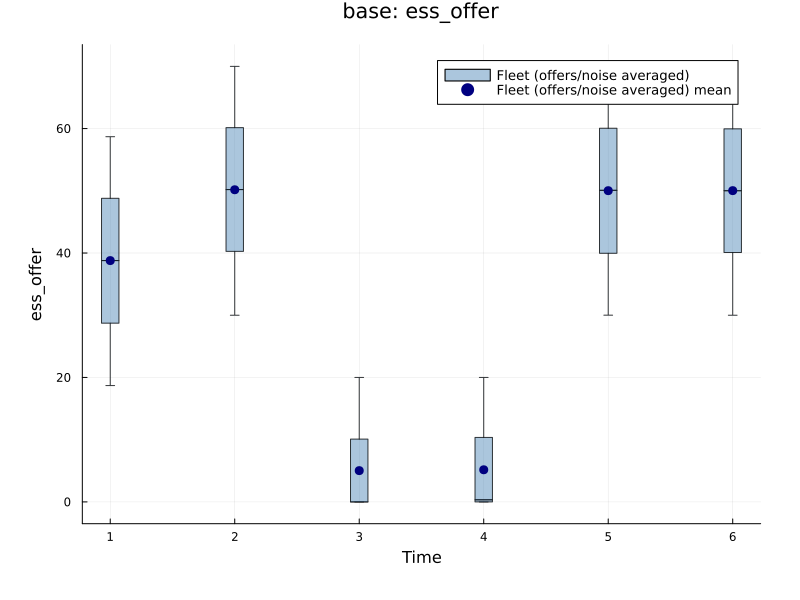

In [30]:
# Choose :ess_offer, :noise, :discharge, :soc, or another numeric interval column.
# Fleet offers/noise are battery means; select battery_view above for one battery.
plot_column = :ess_offer
p_selected = plot_results_column_by_time(
    [multi_uniform_df]; column = plot_column,
    labels = [isnothing(battery_view) ? "Fleet (offers/noise averaged)" : battery_view],
    colors = [:steelblue], mean_colors = [:navy], offsets = [0.0],
    title = "$(scenario): $(plot_column)",
    output_path = joinpath(FIGURE_DIR, "$(plot_column)_by_time.png"),
)
display(p_selected)


# Prices

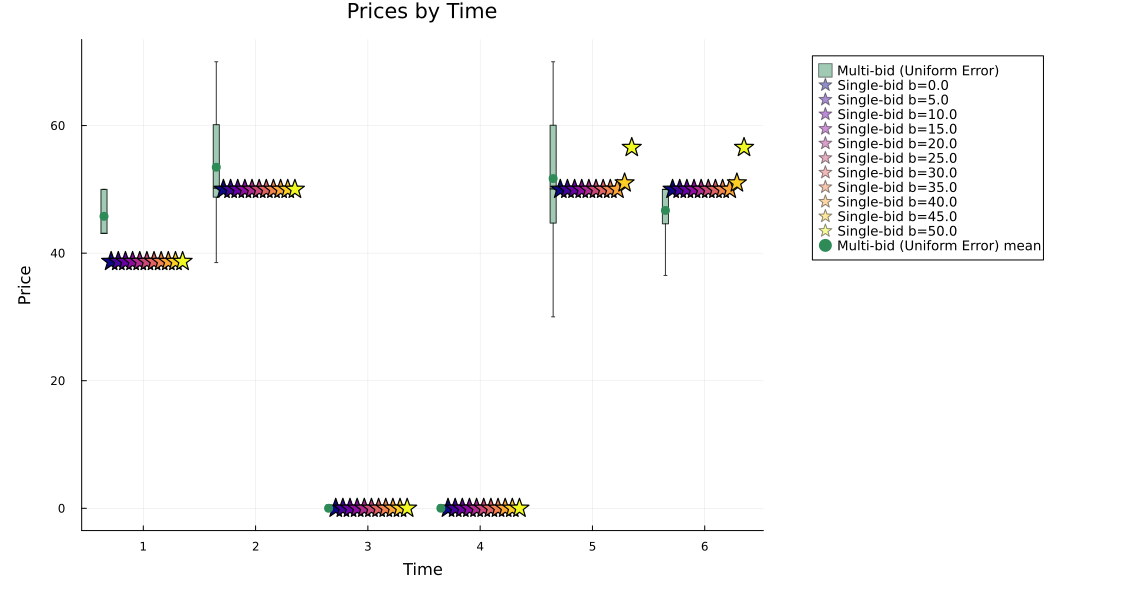

In [31]:
p_price = plot_reference_comparison(
    multi_uniform_df;
    column = :price,
    ylabel = "Price",
    title = "Prices by Time",
    output_path = joinpath(FIGURE_DIR, "prices_by_time.png"),
)
display(p_price)

In [32]:
if has_buy_foresight
    p_price = plot_reference_comparison(
        multi_uniform_df_bid_perfect_foresight;
        column = :price,
        ylabel = "Price",
        title = "Prices by Time (Multi-Bid Buy Foresight)",
        output_path = joinpath(FIGURE_DIR, "prices_by_time_buy_foresight.png"),
    )
    display(p_price)
end


# Charging

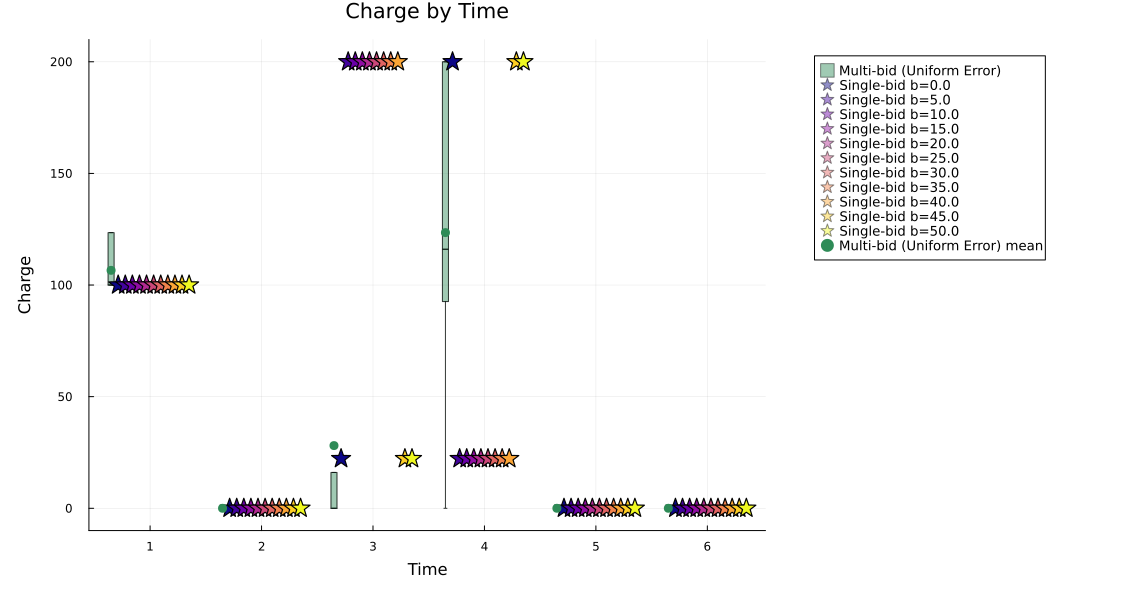

In [33]:
p_charge = plot_reference_comparison(
    multi_uniform_df;
    column = :charge,
    ylabel = "Charge",
    title = "Charge by Time",
    output_path = joinpath(FIGURE_DIR, "charge_by_time.png"),
)
display(p_charge)


In [34]:
if has_buy_foresight
    p_charge = plot_reference_comparison(
        multi_uniform_df_bid_perfect_foresight;
        column = :charge,
        ylabel = "Charge",
        title = "Charge by Time",
        output_path = joinpath(FIGURE_DIR, "charge_by_time_buy_foresight.png"),
    )
    display(p_charge)
end


# ESS Surplus vs. Actual Cost
Multibid samples use an **x** when each battery has a positive discharge and an offer matching the clearing price in at least one interval (the intervals may differ). Other samples use squares. Matching allows 0.01 for CSV rounding. Set `price_setting_mode = :same_interval` in the configuration cell to require both batteries to match in the same interval. Classification uses the raw battery rows, including when plotting one battery.


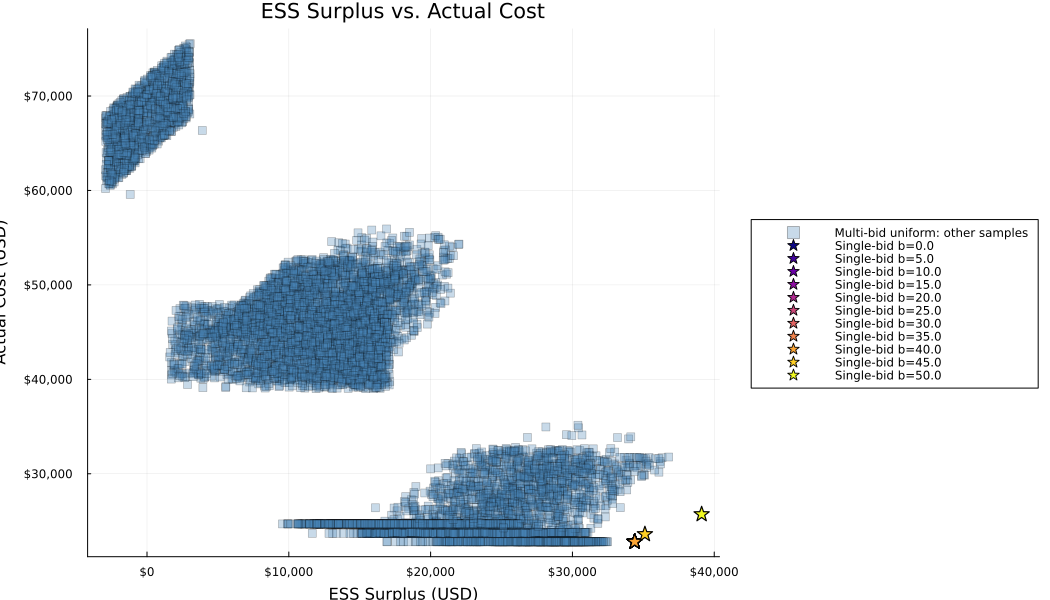

"/Users/nlaws/projects/ferc_841_storage_models/code/figures/bim/base_b0.0_n10000_e20.0_all_references/fleet/ess_surplus_vs_actual_cost.png"

In [35]:

p1 = plot(
    xlabel = "ESS Surplus (USD)",
    ylabel = "Actual Cost (USD)",
    title = "ESS Surplus vs. Actual Cost",
)



plot_multibid_price_markers!(p1, multi_uniform_summary_by_sample,
        "multi_uniform_bid", both_ess_price_samples; label = "Multi-bid uniform")

plot_single_references!(p1, :single_bid_ess_surplus, :single_bid_actual_cost)

display(p1)
savefig(p1, joinpath(FIGURE_DIR, "ess_surplus_vs_actual_cost.png"))


In [36]:
if has_buy_foresight
    p1 = plot(
        xlabel = "ESS Surplus (USD)",
        ylabel = "Actual Cost (USD)",
        title = "ESS Surplus vs. Actual Cost",
    )



    plot_multibid_price_markers!(p1, multi_uniform_summary_by_sample_bid_perfect_foresight,
        "multi_uniform_bid_perfect_foresight", both_ess_price_samples_bid_perfect_foresight; label = "Multi-bid uniform buy foresight")

    plot_single_references!(p1, :single_bid_ess_surplus, :single_bid_actual_cost)

    display(p1)
    savefig(p1, joinpath(FIGURE_DIR, "ess_surplus_vs_actual_cost_buy_foresight.png"))
end


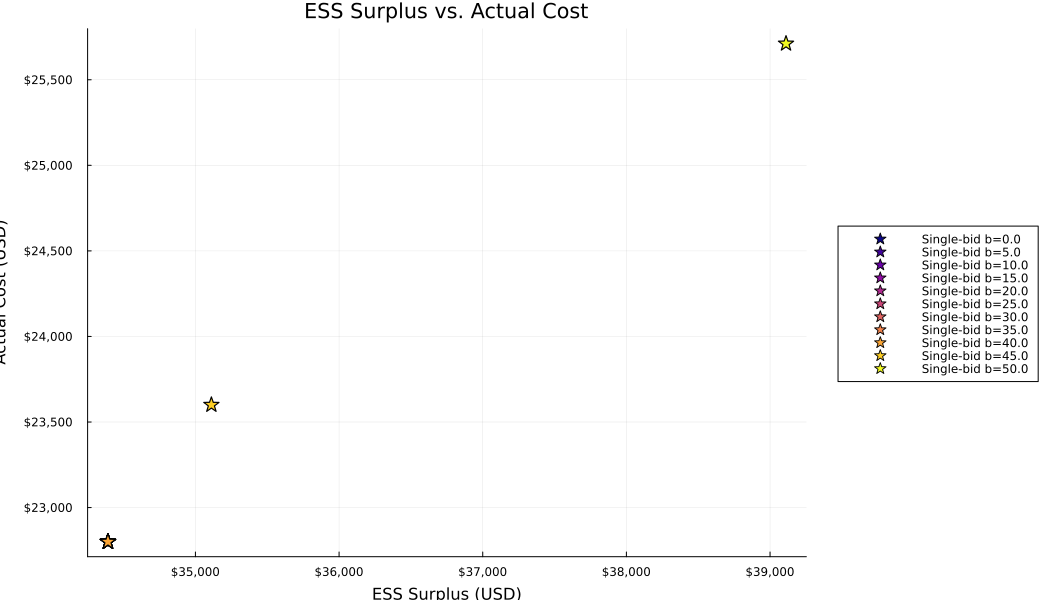

In [37]:
p1 = plot(
    xlabel = "ESS Surplus (USD)",
    ylabel = "Actual Cost (USD)",
    title = "ESS Surplus vs. Actual Cost",
)
plot_single_references!(p1, :single_bid_ess_surplus, :single_bid_actual_cost)

In [38]:
p1 = plot(
    xlabel = "Willingness to Pay (USD)",
    ylabel = "Actual Cost (USD)",
    title = "Willingness to Pay vs. Actual Cost",
)
plot_single_references!(p1, :single_bid_last_ess_bid, :single_bid_actual_cost)
savefig(p1, joinpath(FIGURE_DIR, "willingness_to_pay_vs_actual_cost.png"))

"/Users/nlaws/projects/ferc_841_storage_models/code/figures/bim/base_b0.0_n10000_e20.0_all_references/fleet/willingness_to_pay_vs_actual_cost.png"

# Histograms

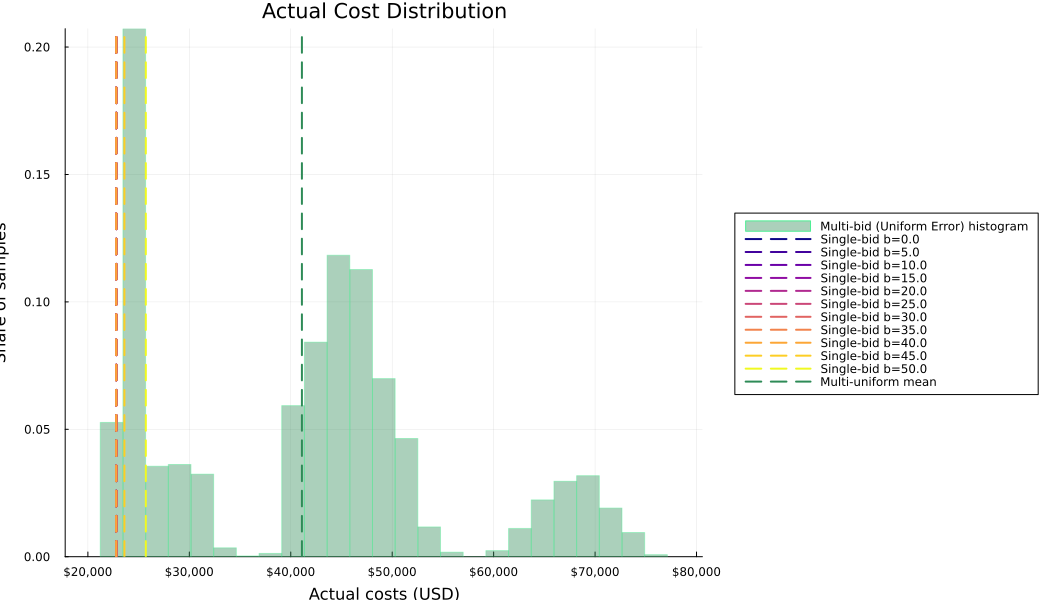

"/Users/nlaws/projects/ferc_841_storage_models/code/figures/bim/base_b0.0_n10000_e20.0_all_references/fleet/actual_cost_distribution.png"

In [39]:
single_vals = single_summary_by_sample.single_bid_actual_cost
multi_uniform_vals = multi_uniform_summary_by_sample.multi_uniform_bid_actual_cost
bins = shared_histogram_bins(single_vals, multi_uniform_vals)

p2 = plot(
    xlabel = "Actual costs (USD)",
    ylabel = "Share of samples",
    title = "Actual Cost Distribution",
    alpha = 0.45,
    color = :darkorange2,
    linecolor = :darkorange4,
    xformatter = dollar_formatter,
)

histogram!(
    p2,
    multi_uniform_vals,
    bins = bins,
    normalize = :probability,
    alpha = 0.4,
    color = :seagreen4,
    linecolor = :seagreen2,
    label = "Multi-bid (Uniform Error) histogram",
    xformatter = dollar_formatter,
)


plot_reference_lines!(p2, :single_bid_actual_cost)
vline!(p2, [mean(multi_uniform_vals)], label = "Multi-uniform mean", linewidth = 2, color = :seagreen4, linestyle = :dash)

display(p2)
savefig(p2, joinpath(FIGURE_DIR, "actual_cost_distribution.png"))


In [40]:
if has_buy_foresight
    single_vals = single_summary_by_sample.single_bid_actual_cost
    multi_uniform_vals = multi_uniform_summary_by_sample_bid_perfect_foresight.multi_uniform_bid_perfect_foresight_actual_cost
    bins = shared_histogram_bins(single_vals, multi_uniform_vals)

    p2 = plot(
        xlabel = "Actual costs (USD)",
        ylabel = "Share of samples",
        title = "Actual Cost Distribution",
        alpha = 0.45,
        color = :darkorange2,
        linecolor = :darkorange4,
        xformatter = dollar_formatter,
    )

    histogram!(
        p2,
        multi_uniform_vals,
        bins = bins,
        normalize = :probability,
        alpha = 0.4,
        color = :seagreen4,
        linecolor = :seagreen2,
        label = "Multi-bid (Uniform Error) buy foresight histogram",
        xformatter = dollar_formatter,
    )


    plot_reference_lines!(p2, :single_bid_actual_cost)
    vline!(p2, [mean(multi_uniform_vals)], label = "Multi-uniform mean", linewidth = 2, color = :seagreen4, linestyle = :dash)

    display(p2)
    savefig(p2, joinpath(FIGURE_DIR, "actual_cost_distribution_buy_foresight.png"))
end


In [41]:
summary_df = DataFrame(
    metric = [
        "mean_cost_to_serve",
        "median_cost_to_serve",
        "min_cost_to_serve",
        "max_cost_to_serve",
        "mean_actual_cost",
        "median_actual_cost",
        "mean_ess_surplus",
        "median_ess_surplus"
    ],
    multi_bid = [
        mean(multi_uniform_summary_by_sample.multi_uniform_bid_cost_to_serve),
        median(multi_uniform_summary_by_sample.multi_uniform_bid_cost_to_serve),
        minimum(multi_uniform_summary_by_sample.multi_uniform_bid_cost_to_serve),
        maximum(multi_uniform_summary_by_sample.multi_uniform_bid_cost_to_serve),
        mean(multi_uniform_summary_by_sample.multi_uniform_bid_actual_cost),
        median(multi_uniform_summary_by_sample.multi_uniform_bid_actual_cost),
        mean(multi_uniform_summary_by_sample.multi_uniform_bid_ess_surplus),
        median(multi_uniform_summary_by_sample.multi_uniform_bid_ess_surplus)
    ]
)
# Each deterministic terminal bid gets its own column rather than an average
# across different reference bids.
for row in eachrow(single_summary_by_sample)
    summary_df[!, "single_bid_b$(row.b)"] = [
        fill(row.single_bid_cost_to_serve, 4)...,
        fill(row.single_bid_actual_cost, 2)...,
        fill(row.single_bid_ess_surplus, 2)...,
    ]
end
summary_df


Row,metric,multi_bid,single_bid_b0.0,single_bid_b5.0,single_bid_b10.0,single_bid_b15.0,single_bid_b20.0,single_bid_b25.0,single_bid_b30.0,single_bid_b35.0,single_bid_b40.0,single_bid_b45.0,single_bid_b50.0
,String,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64
1,mean_cost_to_serve,1.21116e5,115476.0,115476.0,115476.0,115476.0,115476.0,115476.0,115476.0,115476.0,115476.0,116676.0,1.23343e5
2,median_cost_to_serve,1.20753e5,115476.0,115476.0,115476.0,115476.0,115476.0,115476.0,115476.0,115476.0,115476.0,116676.0,1.23343e5
3,min_cost_to_serve,95302.0,115476.0,115476.0,115476.0,115476.0,115476.0,115476.0,115476.0,115476.0,115476.0,116676.0,1.23343e5
4,max_cost_to_serve,1.48327e5,115476.0,115476.0,115476.0,115476.0,115476.0,115476.0,115476.0,115476.0,115476.0,116676.0,1.23343e5
5,mean_actual_cost,41099.1,22800.0,22800.0,22800.0,22800.0,22800.0,22800.0,22800.0,22800.0,22800.0,23600.0,25711.1
6,median_actual_cost,43291.9,22800.0,22800.0,22800.0,22800.0,22800.0,22800.0,22800.0,22800.0,22800.0,23600.0,25711.1
7,mean_ess_surplus,14976.0,34391.1,34391.1,34391.1,34391.1,34391.1,34391.1,34391.1,34391.1,34391.1,35111.1,39111.1
8,median_ess_surplus,14613.6,34391.1,34391.1,34391.1,34391.1,34391.1,34391.1,34391.1,34391.1,34391.1,35111.1,39111.1


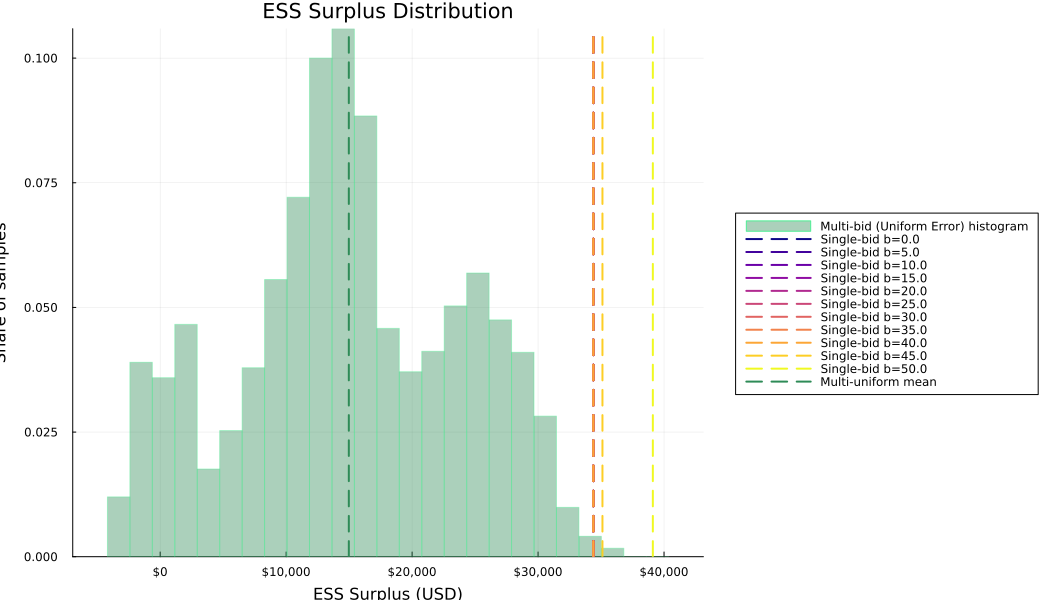

"/Users/nlaws/projects/ferc_841_storage_models/code/figures/bim/base_b0.0_n10000_e20.0_all_references/fleet/ess_surplus_distribution.png"

In [42]:
single_vals = single_summary_by_sample.single_bid_ess_surplus
multi_uniform_vals = multi_uniform_summary_by_sample.multi_uniform_bid_ess_surplus
bins = shared_histogram_bins(single_vals, multi_uniform_vals)

p2 = plot(
    xlabel = "ESS Surplus (USD)",
    ylabel = "Share of samples",
    title = "ESS Surplus Distribution",
    alpha = 0.45,
    color = :darkorange2,
    linecolor = :darkorange4,
    xformatter = dollar_formatter,
)

histogram!(
    p2,
    multi_uniform_vals,
    bins = bins,
    normalize = :probability,
    alpha = 0.4,
    color = :seagreen4,
    linecolor = :seagreen2,
    label = "Multi-bid (Uniform Error) histogram",
    xformatter = dollar_formatter,
)


plot_reference_lines!(p2, :single_bid_ess_surplus)
vline!(p2, [mean(multi_uniform_vals)], label = "Multi-uniform mean", linewidth = 2, color = :seagreen4, linestyle = :dash)

display(p2)
savefig(p2, joinpath(FIGURE_DIR, "ess_surplus_distribution.png"))


In [43]:
if has_buy_foresight
    single_vals = single_summary_by_sample.single_bid_ess_surplus
    multi_uniform_vals = multi_uniform_summary_by_sample_bid_perfect_foresight.multi_uniform_bid_perfect_foresight_ess_surplus
    bins = shared_histogram_bins(single_vals, multi_uniform_vals)

    p2 = plot(
        xlabel = "ESS Surplus (USD)",
        ylabel = "Share of samples",
        title = "ESS Surplus Distribution",
        alpha = 0.45,
        color = :darkorange2,
        linecolor = :darkorange4,
        xformatter = dollar_formatter,
    )

    histogram!(
        p2,
        multi_uniform_vals,
        bins = bins,
        normalize = :probability,
        alpha = 0.4,
        color = :seagreen4,
        linecolor = :seagreen2,
        label = "Multi-bid (Uniform Error) buy foresight histogram",
        xformatter = dollar_formatter,
    )


    plot_reference_lines!(p2, :single_bid_ess_surplus)
    vline!(p2, [mean(multi_uniform_vals)], label = "Multi-uniform mean", linewidth = 2, color = :seagreen4, linestyle = :dash)

    display(p2)
    savefig(p2, joinpath(FIGURE_DIR, "ess_surplus_distribution_buy_foresight.png"))
end


# Dispatch

Row,sample,time,soc,charge,discharge,demand,thermal,renewable,price,ess_bid
,Int64,Int64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64
1,9493,1,360.0,100.0,0.0,100.0,0.0,200.0,43.76,43.1
2,9493,2,0.0,0.0,81.0,200.0,19.0,100.0,50.0,50.0
3,9493,3,57.7778,16.0494,0.0,300.0,0.0,316.05,-0.0,0.0
4,9493,4,777.778,200.0,0.0,300.0,0.0,500.0,-0.0,0.0
5,9493,5,0.0,0.0,175.0,200.0,0.0,25.0,34.44,50.0
6,9493,6,0.0,0.0,0.0,100.0,100.0,-0.0,50.0,40.0


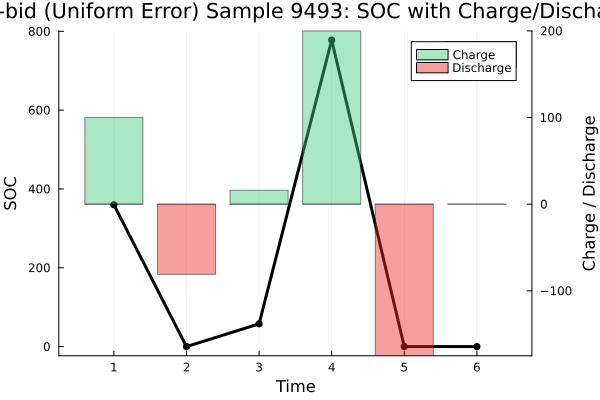

Selected uniform-error multi-bid sample: 9493 | cost_to_serve: 105052.32
Single-bid median cost_to_serve: 115476.0


In [44]:
# --- SOC over time for one uniform-error multi-bid sample with cost_to_serve below the single-bid median ---

cost_threshold = median(single_summary_by_sample.single_bid_cost_to_serve)
sample_pick = :random              # :first | :min_cost | :random

sample_cost = DataFrame(sample = multi_uniform_summary_by_sample.sample, sample_cost_to_serve = multi_uniform_summary_by_sample.multi_uniform_bid_cost_to_serve)
eligible = sample_cost[sample_cost.sample_cost_to_serve .< cost_threshold, :]
if isempty(eligible)
    println("No uniform-error multi-bid samples have cost_to_serve below $(cost_threshold); showing the lowest-cost sample.")
    eligible = sample_cost[[argmin(sample_cost.sample_cost_to_serve)], :]
end

chosen_sample =
    sample_pick == :first    ? eligible.sample[1] :
    sample_pick == :min_cost ? eligible.sample[argmin(eligible.sample_cost_to_serve)] :
    sample_pick == :random   ? rand(eligible.sample) :
    error("sample_pick must be :first, :min_cost, or :random")

ts = multi_uniform_df[multi_uniform_df.sample .== chosen_sample, [:sample, :time, :soc, :charge, :discharge, :demand, :thermal, :renewable, :price, :ess_bid]]
sort!(ts, :time)
display(ts)

p = plot(
    ts.time, ts.soc,
    label = "SOC",
    color = :black,
    linewidth = 3,
    marker = :circle,
    xlabel = "Time",
    ylabel = "SOC",
    title = "Multi-bid (Uniform Error) Sample $(chosen_sample): SOC with Charge/Discharge"
)

p_r = twinx(p)

bar!(
    p_r,
    ts.time, ts.charge,
    label = "Charge",
    color = :seagreen3,
    alpha = 0.45,
    ylabel = "Charge / Discharge"
)

bar!(
    p_r,
    ts.time, -ts.discharge,
    label = "Discharge",
    color = :firebrick2,
    alpha = 0.45
)

chosen_cost = eligible.sample_cost_to_serve[findfirst(==(chosen_sample), eligible.sample)]
println("Selected uniform-error multi-bid sample: ", chosen_sample, " | cost_to_serve: ", round(chosen_cost, digits = 2))
println("Single-bid median cost_to_serve: ", round(cost_threshold, digits = 2))

display(p)
